In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import pypulseq as pp
import MRzeroCore as mr0
import torchkbnufft as tkbn
import torch.nn.functional as F

/opt/conda/lib/python3.13/site-packages/torch/jit/_script.py:1488: DeprecationWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/torch/__config__.py:9: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12050). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._show_config()


Timing check passed successfully


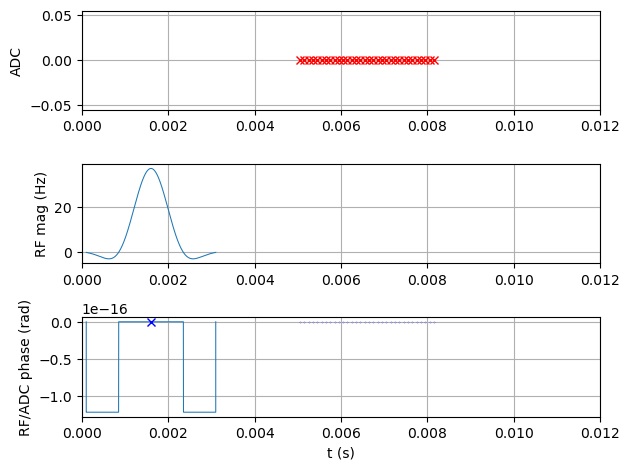

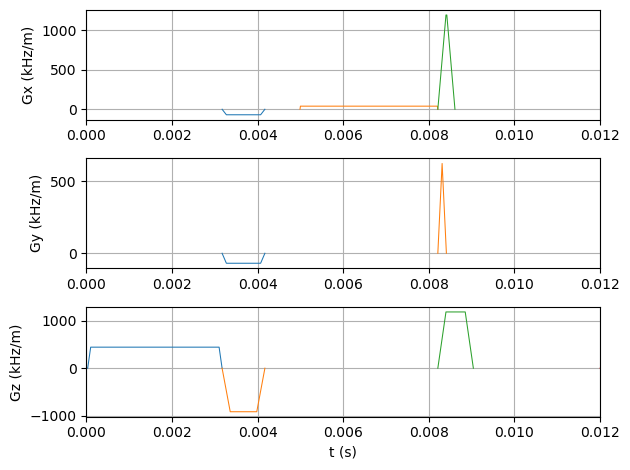

In [2]:
def main(
    plot: bool = False,
    test_report: bool = False,
    write_seq: bool = False,
    seq_filename: str = 'gre_pypulseq.seq',
    *,
    fov: float | tuple[float, float, float] = 256e-3,
    n_x: int = 32,
    n_y: int = 32,
    n_z: int = 32,
    flip_angle_deg: float = 10,
    slice_thickness: float = 3e-3,
    tr: float = 12e-3,
    te: float = 5e-3,
):

    fov_x, fov_y, fov_z = (fov, fov, fov) if isinstance(fov, (int, float)) else fov
    rf_spoiling_inc = 0

    # Set system limits
    system = pp.Opts(
        max_grad=28,
        grad_unit='mT/m',
        max_slew=150,
        slew_unit='T/m/s',
        rf_ringdown_time=20e-6,
        rf_dead_time=100e-6,
        adc_dead_time=10e-6,
    )

    seq = pp.Sequence(system)

    # Create slice selection pulse and gradient
    rf, gz, _ = pp.make_sinc_pulse(
        flip_angle=np.deg2rad(flip_angle_deg),
        duration=3e-3,
        slice_thickness=slice_thickness,
        apodization=0.42,
        time_bw_product=4,
        system=system,
        return_gz=True,
        delay=system.rf_dead_time,
        use='excitation',
    )

    # Define other gradients and ADC events
    delta_kx = 1 / fov_x
    delta_ky = 1 / fov_y
    delta_kz = 1 / fov_z
    gx = pp.make_trapezoid(channel='x', flat_area=n_x * delta_kx, flat_time=3.2e-3, system=system)
    adc = pp.make_adc(num_samples=n_x, duration=gx.flat_time, delay=gx.rise_time, system=system)
    gx_pre = pp.make_trapezoid(channel='x', area=-gx.area / 2, duration=1e-3, system=system)
    gz_reph = pp.make_trapezoid(channel='z', area=-gz.area / 2, duration=1e-3, system=system)
    phase_areas = (np.arange(n_y) - n_y / 2) * delta_ky
    phase_areas_z = (np.arange(n_z) - n_z / 2) * delta_kz

    # Gradient spoiling
    gx_spoil = pp.make_trapezoid(channel='x', area=2 * n_x * delta_kx, system=system)
    gy_spoil = pp.make_trapezoid(channel='y', area=2 * n_y * delta_ky, system=system)
    gz_spoil = pp.make_trapezoid(channel='z', area=4 / fov_z, system=system)

    EPS: float = 1e-12

    # Calculate timing
    te_delay = (
        te
        - (pp.calc_duration(gz, rf) - pp.calc_rf_center(rf)[0] - rf.delay)
        - pp.calc_duration(gx_pre)
        - pp.calc_duration(gx) / 2
        - EPS
    )
    te_delay = np.ceil(te_delay / seq.grad_raster_time) * seq.grad_raster_time

    tr_delay = tr - pp.calc_duration(gz, rf) - pp.calc_duration(gx_pre) - pp.calc_duration(gx) - te_delay
    tr_delay = np.ceil(tr_delay / seq.grad_raster_time) * seq.grad_raster_time

    assert np.all(te_delay >= 0)
    assert np.all(tr_delay >= pp.calc_duration(gx_spoil, gy_spoil, gz_spoil))

    rf_phase = 0
    rf_inc = 0

    # New 3D loop structure
    for i_z in range(n_z):  # Outer loop for Z-partitions
        for i_phase in range(n_y):  # Inner loop for Y-phase encoding
            # --- Keeping your existing RF phase math ---
            rf.phase_offset = rf_phase / 180 * np.pi
            adc.phase_offset = rf_phase / 180 * np.pi
            rf_inc = divmod(rf_inc + rf_spoiling_inc, 360.0)[1]
            rf_phase = divmod(rf_phase + rf_inc, 360.0)[1]

            # Block 1: Excitation
            seq.add_block(rf, gz)

            # Block 2: 3D Pre-phasing (X, Y, and Z combined)
            gy_pre = pp.make_trapezoid(
                channel='y',
                area=phase_areas[i_phase],
                duration=pp.calc_duration(gx_pre),
                system=system,
            )
            # Combine slice rephasing with 3D phase encoding
            gz_pre = pp.make_trapezoid(
                channel='z',
                area=phase_areas_z[i_z] - gz.area / 2,
                duration=pp.calc_duration(gx_pre),
                system=system,
            )
            seq.add_block(gx_pre, gy_pre, gz_pre)

            # Block 3: Delay and Readout
            seq.add_block(pp.make_delay(te_delay))
            seq.add_block(gx, adc)

            # Block 4: 3D Spoiling & TR Delay
            # Rewind Y normally
            gy_rewind = pp.make_trapezoid(channel='y', area=-gy_pre.area, system=system)

            # COMBINE the Z-rewinder and Z-spoiler areas into one single event
            gz_combined_spoil = pp.make_trapezoid(
                channel='z',
                area=gz_spoil.area - gz_pre.area,
                system=system
            )

            # Add the block with only ONE event per channel
            seq.add_block(pp.make_delay(tr_delay), gx_spoil, gy_rewind, gz_combined_spoil)

    ok, error_report = seq.check_timing()
    if ok:
        print('Timing check passed successfully')
    else:
        print('Timing check failed. Error listing follows:')
        [print(e) for e in error_report]

    if test_report:
        print(seq.test_report())

    if plot:
        seq.plot(time_range=(0.0, tr))

    seq.set_definition('FOV', [fov_x, fov_y, fov_z])
    seq.set_definition('Name', 'gre')

    if write_seq:
        seq.write("3D GRE.seq")

    return seq

if __name__ == '__main__':
    main(plot=True, write_seq=True)

In [ ]:
n_x: int = 32
n_y: int = 32
n_z: int = 32

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

raw_data = np.fromfile("subject04_crisp_v.rawb", dtype=np.uint8).reshape(362, 434, 362)

brain_mask = (raw_data >= 1) & (raw_data <= 3)
cleaned_brain = raw_data * brain_mask

#Proton Density map
pd_signal = np.zeros_like(raw_data, dtype=np.float32)
pd_signal[raw_data == 1] = 1.0  
pd_signal[raw_data == 2] = 0.8  
pd_signal[raw_data == 3] = 0.7  

phantom_tensor = torch.from_numpy(pd_signal).to(device)

input_5d = phantom_tensor.view(1, 1, 362, 434, 362)

phantom_small = F.interpolate(
    input_5d,
    size=(n_z, n_y, n_x),
    mode='trilinear'
).squeeze()

pd_map = phantom_small
pd_map = pd_map.permute(2,1,0)

t1_map = torch.zeros_like(pd_map)
t1_map = torch.where(pd_map > 0.9, 4.0, t1_map)   # CSF: 4s
t1_map = torch.where((pd_map <= 0.9) & (pd_map > 0.75), 1.3, t1_map) 
t1_map = torch.where((pd_map <= 0.75) & (pd_map > 0.1), 0.9, t1_map)


t2_map = torch.zeros_like(pd_map)
t2_map = torch.where(pd_map > 0.9, 0.5, t2_map)   
t2_map = torch.where((pd_map <= 0.9) & (pd_map > 0.75), 0.08, t2_map) 
t2_map = torch.where((pd_map <= 0.75) & (pd_map > 0.1), 0.07, t2_map) 
#t1_map = torch.where(pd_map > 0.5, 0.8, 1.2)
#t2_map = torch.where(pd_map > 0.5, 0.05, 0.09)
t2dash_map = torch.full_like(pd_map, 0.04) 
d_map = torch.zeros_like(pd_map)           
b0_map = torch.zeros_like(pd_map)          
b1_map = torch.ones_like(pd_map).unsqueeze(0)            
coil_sens = torch.ones_like(pd_map).unsqueeze(0)       
fov_size = torch.tensor([0.256, 0.256, 0.256], device=device)               


obj = mr0.VoxelGridPhantom(
    pd_map,     
    t1_map,     
    t2_map,     
    t2dash_map, 
    d_map,      
    b0_map,     
    b1_map,     
    coil_sens,  
    fov_size    
)

signal,_ = mr0.util.simulate("3D GRE.seq", obj)

signal = signal.squeeze().cpu().numpy()
print(signal.shape)

kspace = signal.reshape(n_z, n_y, n_x)

idx = 0
for i_z in range(n_z):
    for i_y in range(n_y):
        kspace[i_z, i_y, :] = signal[idx:idx + n_x]
        idx += n_x

img = np.fft.ifftn(np.fft.ifftshift(kspace, axes=(0,1,2)), axes=(0,1,2))
img = np.fft.fftshift(img, axes=(0,1,2))

center_slice = n_z // 2

plt.figure(figsize=(6, 6))
plt.imshow(np.log(np.abs(kspace[n_z//2]) + 1e-6), cmap='gray')
plt.imshow(np.abs(img[center_slice, :, :]), cmap='gray')
plt.title(f"Reconstructed 3D GRE - Axial Slice {center_slice}")
plt.axis('off')
plt.show()

>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.005754001 s
Compute Graph
Computing Graph: 0.22565396 s
Analyze Graph
Analyzing Graph: 0.011407403 s
Converting Rust -> Python: 0.15877254 s
<<<< Rust <<<<
